In [ ]:
  import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: []


In [ ]:
import tensorflow as tf

print("GPU:", tf.config.list_physical_devices('GPU'))

GPU: []


In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Use smaller dataset for faster CPU training
X_train = X_train[:5000]
y_train = y_train[:5000]

X_test = X_test[:1000]
y_test = y_test[:1000]

# Normalize images
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

print("Training Images:", X_train.shape)
print("Testing Images:", X_test.shape)
print("Number of Classes:", len(class_names))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1780s 10us/step
Training Images: (5000, 32, 32, 3)
Testing Images: (1000, 32, 32, 3)
Number of Classes: 10


In [4]:
# Build CNN model from scratch

from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

# Compile model
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history_cnn = cnn_model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

cnn_loss, cnn_accuracy = cnn_model.evaluate(
    X_test, y_test, verbose=0
)

print("CNN Test Accuracy:", round(cnn_accuracy * 100, 2), "%")

Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 112ms/step - accuracy: 0.2118 - loss: 2.1166 - val_accuracy: 0.3300 - val_loss: 1.8795
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - accuracy: 0.3252 - loss: 1.8322 - val_accuracy: 0.3730 - val_loss: 1.7520
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - accuracy: 0.3850 - loss: 1.6906 - val_accuracy: 0.4390 - val_loss: 1.6328
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - accuracy: 0.4225 - loss: 1.5914 - val_accuracy: 0.4270 - val_loss: 1.5904
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - accuracy: 0.4395 - loss: 1.5502 - val_accuracy: 0.4490 - val_loss: 1.5434
CNN Test Accuracy: 44.8 %


In [6]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, Model

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(96, 96, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build transfer learning model
inputs = layers.Input(shape=(32, 32, 3))

# Resize images for MobileNetV2
x = layers.Resizing(96, 96)(inputs)

# Convert pixel values from [0, 1] to [-1, 1]
x = layers.Rescaling(2.0, offset=-1)(x)

# Extract pretrained features
x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(10, activation="softmax")(x)

mobilenet_model = Model(inputs, outputs)

# Compile model
mobilenet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
history_mobilenet = mobilenet_model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

mobilenet_loss, mobilenet_accuracy = mobilenet_model.evaluate(
    X_test, y_test, verbose=0
)

print("MobileNetV2 Test Accuracy:",
      round(mobilenet_accuracy * 100, 2), "%")

Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 46s 649ms/step - accuracy: 0.5182 - loss: 1.5043 - val_accuracy: 0.7690 - val_loss: 0.7250
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 39s 620ms/step - accuracy: 0.7692 - loss: 0.7083 - val_accuracy: 0.8030 - val_loss: 0.6232
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 40s 599ms/step - accuracy: 0.8010 - loss: 0.5771 - val_accuracy: 0.8220 - val_loss: 0.5703
MobileNetV2 Test Accuracy: 83.1 %


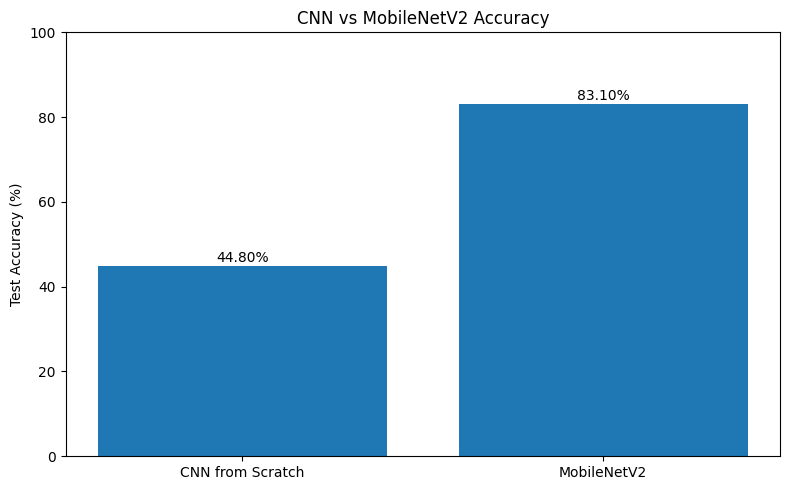

In [8]:
import matplotlib.pyplot as plt

models = ["CNN from Scratch", "MobileNetV2"]
accuracies = [
    cnn_accuracy * 100,
    mobilenet_accuracy * 100
]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, accuracies)

plt.title("CNN vs MobileNetV2 Accuracy")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

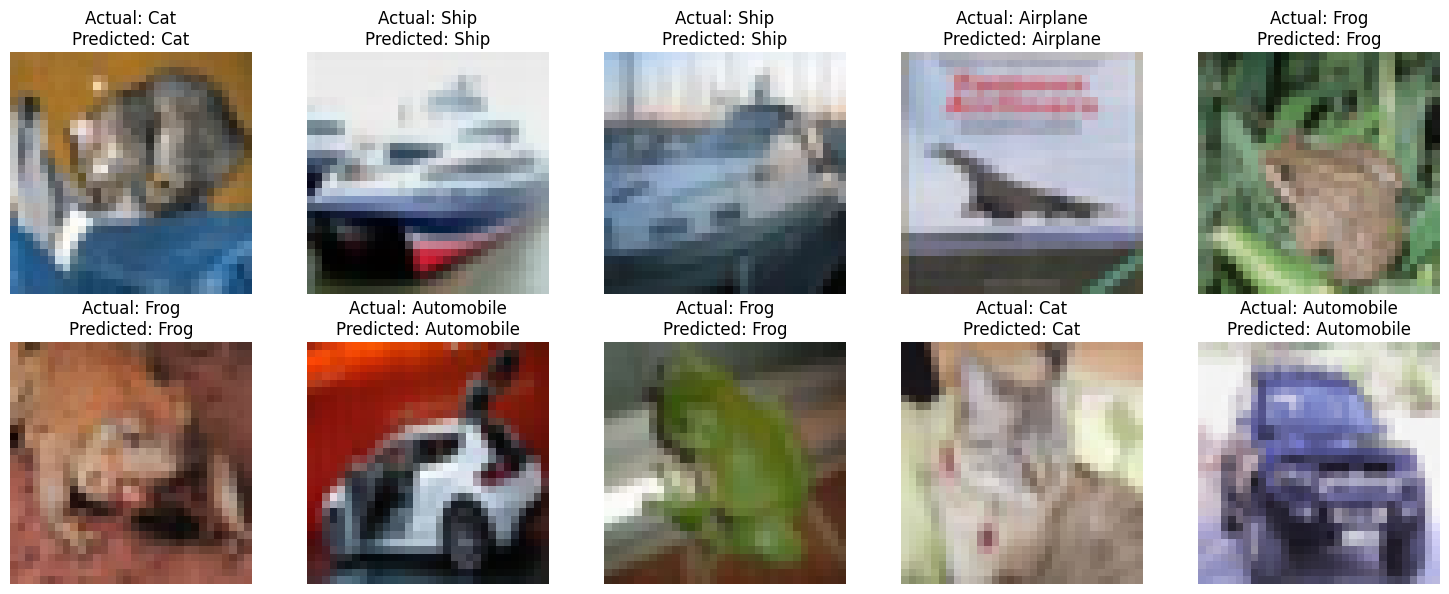

In [9]:
import numpy as np
import matplotlib.pyplot as plt

predictions = mobilenet_model.predict(
    X_test[:10], verbose=0
)

predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i])

    actual = class_names[int(y_test[i][0])]
    predicted = class_names[predicted_labels[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.savefig("image_predictions.png")
plt.show()

In [10]:
print("===== DAY 21 RESULTS =====")

print(f"CNN Accuracy: {cnn_accuracy * 100:.2f}%")
print(f"MobileNetV2 Accuracy: {mobilenet_accuracy * 100:.2f}%")

improvement = (
    mobilenet_accuracy - cnn_accuracy
) * 100

print(f"Improvement: {improvement:.2f} percentage points")

print("\nDay 21 Completed Successfully!")

===== DAY 21 RESULTS =====
CNN Accuracy: 44.80%
MobileNetV2 Accuracy: 83.10%
Improvement: 38.30 percentage points

Day 21 Completed Successfully!
